<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/11_PyStac_Crop_Area.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pystac-client stackstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.0 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
   'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [67.311429, 43.551136, 67.386264, 43.59439]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2023'
)

In [7]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['nir08', 'preview', 'thumbnail', 'green', 'product_metadata', 'aot', 'tileinfo_metadata', 'swir16', 'granule_metadata', 'red', 'wvp', 'cloud', 'blue', 'nir', 'swir22', 'snow', 'visual', 'rededge2', 'rededge3', 'rededge1', 'scl', 'coastal', 'nir09']
  warnings.warn(


In [8]:
len(items)

144

In [9]:
items[0].properties['proj:code']

'EPSG:32642'

In [10]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [13]:
import stackstac

In [14]:
ds_stack = stackstac.stack(
    items,
    assets = ['red','nir','scl'],
    bounds_latlon = roi,
    resolution = 10,
    epsg = 32642
)

In [15]:
ds= (
    ds_stack.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [16]:
mask = ds.scl.isin([3,8,9,10]).astype(int)
ds_mask = ds[['nir','red']].where(mask == 0)

In [17]:
nir = ds['nir']
red = ds['red']
ndvi = (nir - red) / (nir + red)

In [18]:
ndvi_weekly = ndvi.resample(time = 'W').max('time')

In [19]:
from dask.diagnostics import ProgressBar

In [20]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [21]:
with ProgressBar():
  ndvi_weekly = ndvi_weekly.compute()

[########################################] | 100% Completed | 58.12 s


In [22]:
from scipy.signal import savgol_filter

In [23]:
ndvi_val = ndvi_weekly.values

In [24]:
ndvi_weekly

<xarray.DataArray (time: 52, y: 493, x: 615)> Size: 126MB
array([[[0.06822262, 0.06997743, 0.05763952, ..., 0.07058344,
         0.07723743, 0.07252216],
        [0.06504065, 0.06502956, 0.05214582, ..., 0.06321839,
         0.07536467, 0.07025291],
        [0.05570776, 0.05112851, 0.05723592, ..., 0.07175072,
         0.08079578, 0.07847082],
        ...,
        [0.0687885 , 0.06446622, 0.06913828, ..., 0.11172414,
         0.09954751, 0.09812871],
        [0.07153886, 0.07478081, 0.07739938, ..., 0.10178001,
         0.09312839, 0.10655738],
        [0.08289054, 0.07758159, 0.07995736, ..., 0.09346642,
         0.10111317, 0.09591556]],

       [[0.18805121, 0.1635468 , 0.16620954, ..., 0.15158124,
         0.14001077, 0.13306039],
        [0.16321374, 0.1704711 , 0.155902  , ..., 0.14670659,
         0.1411158 , 0.12441093],
        [0.14737379, 0.16309227, 0.15178325, ..., 0.14341847,
         0.11400221, 0.1173157 ],
...
        [0.05478842, 0.05410628, 0.04749455, ..., 0.05737977,
         0.05273766, 0.04945055],
        [0.057041  , 0.05424322, 0.04766444, ..., 0.0565046 ,
         0.05259609, 0.05071967],
        [0.06063269, 0.05281385, 0.04966571, ..., 0.05504587,
         0.05469278, 0.04534606]],

       [[0.19258203, 0.18622628, 0.17586796, ..., 0.13898788,
         0.15242593, 0.1557047 ],
        [0.17619603, 0.18379161, 0.1861421 , ..., 0.13674033,
         0.14155844, 0.16888046],
        [0.17978173, 0.17893477, 0.18677281, ..., 0.13809206,
         0.158831  , 0.15755208],
        ...,
        [0.1932299 , 0.18526786, 0.18619437, ..., 0.1232493 ,
         0.12078652, 0.14550265],
        [0.19810427, 0.19174041, 0.16176471, ..., 0.12534819,
         0.13937754, 0.13912476],
        [0.18960674, 0.18301158, 0.1848783 , ..., 0.11065292,
         0.10006716, 0.15432526]]])
Coordinates:
  * time     (time) datetime64[ns] 416B 2023-01-08 2023-01-15 ... 2023-12-31
  * y        (y) float64 4kB 4.828e+06 4.828e+06 ... 4.823e+06 4.823e+06
  * x        (x) float64 5kB 3.636e+05 3.636e+05 ... 3.697e+05 3.697e+05

In [25]:
ndvi_val.shape

(52, 493, 615)

In [26]:
help(savgol_filter)

Help on function savgol_filter in module scipy.signal._savitzky_golay:

savgol_filter(
    x,
    window_length,
    polyorder,
    deriv=0,
    delta=1.0,
    axis=-1,
    mode='interp',
    cval=0.0
)
    Apply a Savitzky-Golay filter to an array.

    This is a 1-D filter. If `x`  has dimension greater than 1, `axis`
    determines the axis along which the filter is applied.

    Parameters
    ----------
    x : array_like
        The data to be filtered. If `x` is not a single or double precision
        floating point array, it will be converted to type ``numpy.float64``
        before filtering.
    window_length : int
        The length of the filter window (i.e., the number of coefficients).
        If `mode` is 'interp', `window_length` must be less than or equal
        to the size of `x`.
    polyorder : int
        The order of the polynomial used to fit the samples.
        `polyorder` must be less than `window_length`.
    deriv : int, optional
        The order of the d

In [27]:
ndvi_interp = ndvi_weekly.interpolate_na(dim = 'time', method = 'linear')
ndvi_interp = ndvi_interp.ffill('time').bfill('time')

In [28]:
ndvi_filter = savgol_filter(
    ndvi_interp.values,
    window_length = 10,
    polyorder = 2,
    axis = 0,
    mode = 'interp'
)

In [29]:
import xarray as xr

In [30]:
ndvi_sg = xr.DataArray(
    ndvi_filter,
    dims = ndvi_weekly.dims,
    coords = ndvi_weekly.coords
)

In [31]:
ndvi_monthly = ndvi_sg.resample(time = 'M').mean('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


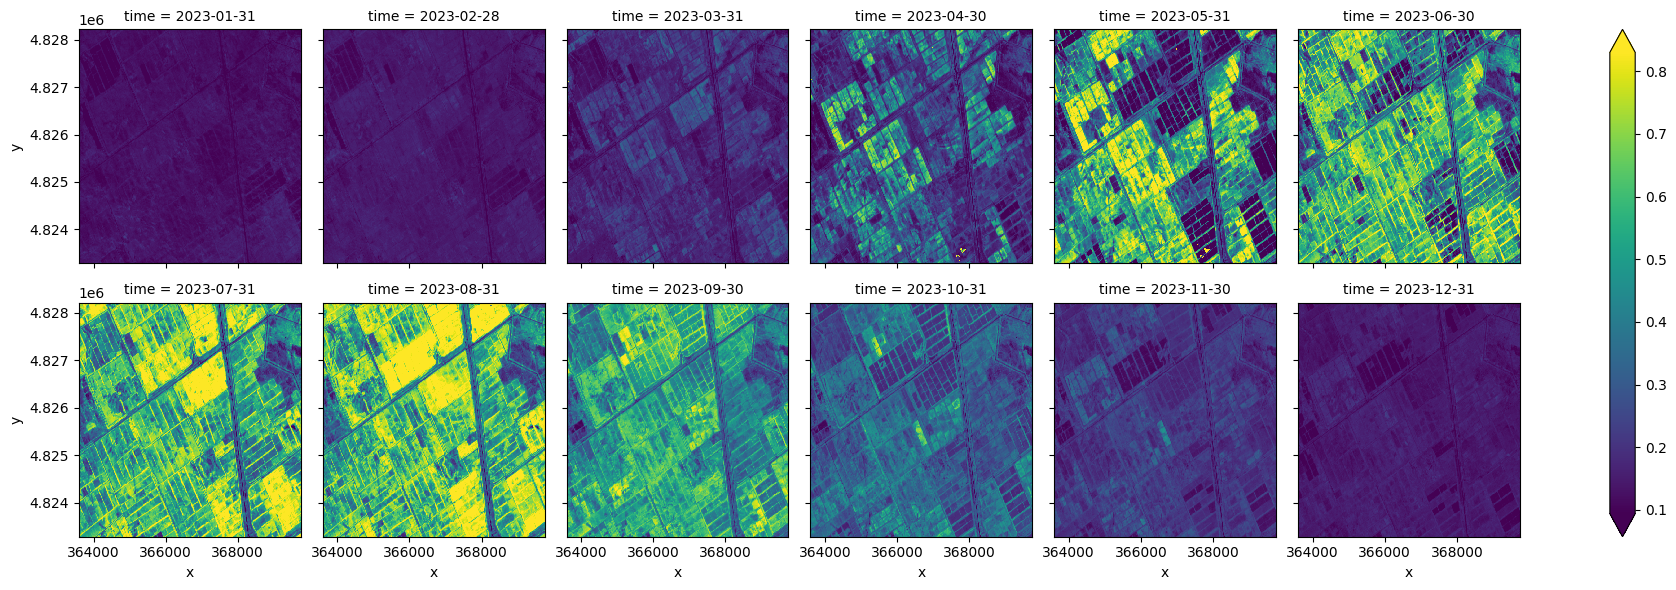

In [32]:
ndvi_monthly.plot(robust = True, col = 'time', col_wrap = 6)

In [33]:
from skimage.filters import threshold_otsu

In [34]:
thr = threshold_otsu(ndvi_monthly.values)

In [35]:
thr_list = []

for i in ndvi_monthly.time.values:
  img_sel = ndvi_monthly.sel(time = i).values
  thr_sel = threshold_otsu(img_sel)
  thr_list.append(thr_sel)

In [36]:
thr_xr = xr.DataArray(
    thr_list,
    dims = ['time'],
    coords = {'time': ndvi_monthly.time.values}
)

In [37]:
crop_layer = (ndvi_monthly >= thr_xr).astype(int)

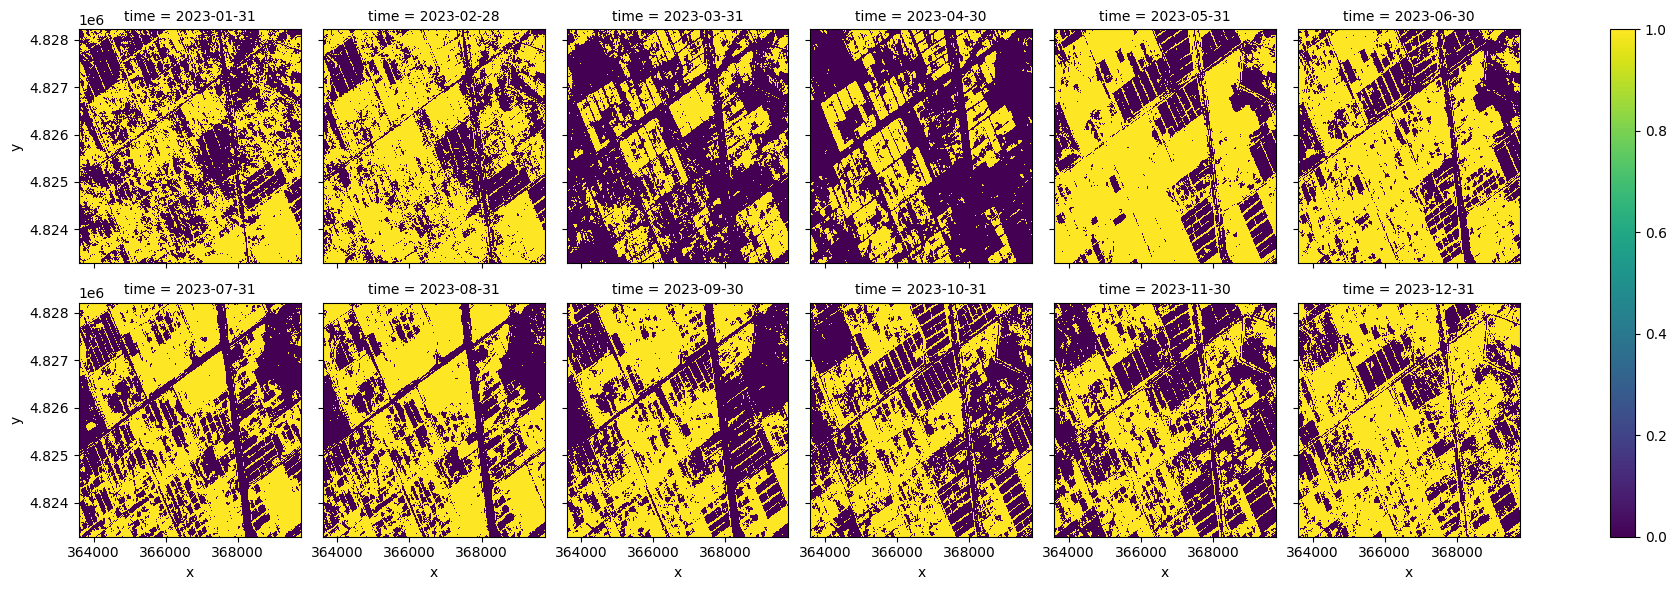

In [38]:
crop_layer.plot(col = 'time', col_wrap = 6)

In [39]:
crop_pixels = (crop_layer == 1).sum(dim = ['x','y'])
crop_area = crop_pixels * ((10 * 10)/1e6)

<Axes: xlabel='time'>

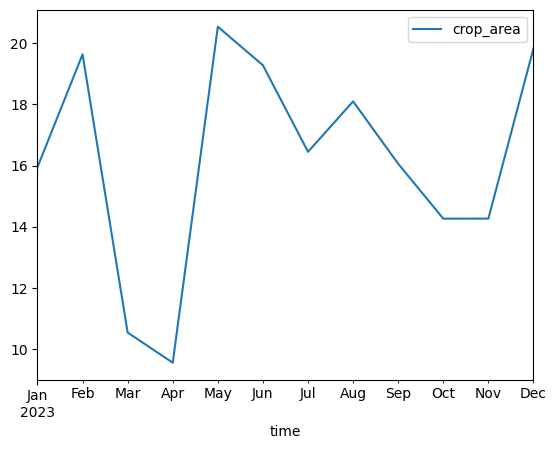

In [40]:
crop_area.to_dataframe('crop_area').plot()

In [41]:
crop_area.to_dataframe('crop_area').to_csv('crop_area.csv')